#  CHAPITRE 1 — COMPRÉHENSION DU PROBLÈME MÉTIER

La fraude aux paiements électroniques représente un enjeu majeur pour les institutions financières et les plateformes de commerce en ligne : elle génère chaque année des pertes de plusieurs dizaines de milliards de dollars, dégrade la confiance des clients et impose des coûts de gestion (rétrofacturations, enquêtes, sanctions réglementaires). Les fraudeurs adaptent en permanence leurs techniques, ce qui rend les règles métier statiques rapidement obsolètes et justifie le recours à des approches analytiques et statistiques d'apprentissage automatique.

La problématique est double. D'une part, la fraude est un événement **rare** : le jeu de données IEEE-CIS, publié par Vesta Corporation, présente un déséquilibre marqué entre transactions légitimes et frauduleuses, ce qui biaise les méthodes classiques et rend l'accuracy trompeuse. D'autre part, un système de détection doit arbitrer entre deux coûts asymétriques : laisser passer une fraude (faux négatif) ou bloquer à tort un client légitime (faux positif). La question centrale est donc : *quelles caractéristiques des transactions, des cartes et des appareils permettent de distinguer efficacement les transactions frauduleuses, et dans quelle mesure peut-on les détecter de manière fiable ?*

L'objectif du projet est de conduire une démarche complète de Data Analytics, Business Intelligence et Data Science : (i) comprendre et préparer les données issues de la fusion des tables transaction et identité ; (ii) réaliser une analyse exploratoire et statistique rigoureuse (tests d'hypothèses, ACP, clustering, détection d'anomalies) ; (iii) restituer les résultats dans un tableau de bord Power BI ; (iv) construire et comparer des modèles prédictifs (régression logistique, Random Forest, XGBoost) ; (v) déployer une application Streamlit de prédiction et d'interprétabilité (SHAP).

# CHAPITRE 2 — COMPRÉHENSION DES DONNÉES

## 2.1 Importation des bibliothèques

In [1]:
# Manipulation de données
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import plotly.express as px

# Statistiques et pré-traitement
from scipy import stats
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

import warnings
warnings.filterwarnings("ignore")

# Paramètres d'affichage
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})

SEED = 42
DATA_DIR = "../data/"  

Les bibliothèques de manipulation (pandas, numpy), de visualisation (seaborn, matplotlib, plotly, missingno) et de traitement statistique (scipy, scikit-learn) sont chargées sans erreur.

## 2.2 Chargement et fusion des données

In [2]:
# Chargement des deux tables du jeu d'entraînement
train_transaction = pd.read_csv(DATA_DIR + "train_transaction.csv")
train_identity    = pd.read_csv(DATA_DIR + "train_identity.csv")

print("train_transaction :", train_transaction.shape)
print("train_identity    :", train_identity.shape)

# Fusion sur TransactionID (left join : on conserve toutes les transactions)
df_raw = pd.merge(
    train_transaction,
    train_identity,
    on="TransactionID",
    how="left"
)
print("df_raw (fusionné) :", df_raw.shape)

# Libération mémoire des tables sources
del train_transaction, train_identity

train_transaction : (590540, 394)
train_identity    : (144233, 41)
df_raw (fusionné) : (590540, 434)


### Interprétation — Chargement et fusion

La table transaction contient environ 590 540 lignes et 394 colonnes ; la table identité environ 144 233 lignes et 41 colonnes. Après fusion à gauche, df_raw conserve les 590 540 transactions et environ 434 colonnes.

Seule une partie des transactions (environ 24 %) possède des informations d'identité (appareil, navigateur, réseau) : les colonnes issues de la table identité contiennent donc mécaniquement beaucoup de valeurs manquantes après fusion.

**Intérêt métier.** Le choix du left join évite de perdre des transactions et donc des cas de fraude. L'absence d'information d'identité est elle-même potentiellement informative pour la détection de fraude.

## 2.3 Dimensions

In [3]:
n_lignes, n_colonnes = df_raw.shape
print(f"Nombre de transactions (lignes) : {n_lignes:,}")
print(f"Nombre de variables (colonnes)  : {n_colonnes}")
print(f"Mémoire utilisée                : {df_raw.memory_usage(deep=True).sum() / 1024**2:,.0f} Mo")

Nombre de transactions (lignes) : 590,540
Nombre de variables (colonnes)  : 434
Mémoire utilisée                : 2,514 Mo


### Interprétation — Dimensions

 Le jeu de données comporte plusieurs centaines de milliers de lignes et plus de 430 colonnes, pour une empreinte mémoire de plusieurs Go.

Il s'agit d'un jeu de données de grande dimension (haute dimensionnalité) : la sélection de variables, la réduction mémoire et la réduction de dimension (ACP) seront nécessaires.

Les volumes sont représentatifs d'un système de paiement réel et imposent des traitements efficaces.

## 2.4 Aperçu des données

In [4]:
# Premières lignes (sous-ensemble de colonnes clés pour la lisibilité)
cols_apercu = ["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD",
               "card1", "card4", "card6", "addr1", "P_emaildomain", "DeviceType", "DeviceInfo"]
df_raw[cols_apercu].head(10)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card4,card6,addr1,P_emaildomain,DeviceType,DeviceInfo
0,2987000,0,86400,68.500,W,13926,discover,credit,315.000,NaN,NaN,NaN
1,2987001,0,86401,29.000,W,2755,mastercard,credit,325.000,gmail.com,NaN,NaN
2,2987002,0,86469,59.000,W,4663,visa,debit,330.000,outlook.com,NaN,NaN
3,2987003,0,86499,50.000,W,18132,mastercard,debit,476.000,yahoo.com,NaN,NaN
4,2987004,0,86506,50.000,H,4497,mastercard,credit,420.000,gmail.com,mobile,SAMSUNG SM-G892A Build/NRD90M
5,2987005,0,86510,49.000,W,5937,visa,debit,272.000,gmail.com,NaN,NaN
6,2987006,0,86522,159.000,W,12308,visa,debit,126.000,yahoo.com,NaN,NaN
7,2987007,0,86529,422.500,W,12695,visa,debit,325.000,mail.com,NaN,NaN
8,2987008,0,86535,15.000,H,2803,visa,debit,337.000,anonymous.com,mobile,iOS Device
9,2987009,0,86536,117.000,W,17399,mastercard,debit,204.000,yahoo.com,NaN,NaN


### Interprétation 

**Ce qui est observé.** Chaque ligne représente une transaction identifiée par TransactionID, avec son montant, un produit, des attributs de carte, une adresse, un domaine email et, lorsqu'ils existent, des informations sur l'appareil.

**Intérêt métier.** L'anonymisation protège les données clients mais limite l'interprétation métier directe : l'analyse devra s'appuyer sur des comportements statistiques plutôt que sur le sens littéral de chaque variable.

## 2.5 Types des variables

In [5]:
# Répartition des types
print(df_raw.dtypes.value_counts())

# Variables de type object (catégorielles)
cols_cat_brut = df_raw.select_dtypes(include="object").columns.tolist()
print(f"\n{len(cols_cat_brut)} variables catégorielles :")
print(cols_cat_brut)

float64    399
object      31
int64        4
Name: count, dtype: int64

31 variables catégorielles :
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


### Interprétation — Types des variables

La grande majorité des colonnes sont numériques (float64 et int64) ; une minorité (31) est de type str : ProductCD, card4, card6, P_emaildomain, R_emaildomain, M1–M9, id_12, id_15, id_16, id_23, id_27 à id_34, DeviceType, DeviceInfo.

Les variables de type str devront être encodées avant toute modélisation. Certaines colonnes numériques (card1, addr1, codes) sont en réalité des identifiants catégoriels.



## 2.6 Statistiques descriptives

In [6]:
# Statistiques descriptives des variables numériques clés
cols_num_cles = ["TransactionDT", "TransactionAmt", "dist1", "dist2", "C1", "C2", "D1", "D2"]
df_raw[cols_num_cles].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
TransactionDT,"590,540.000","7,372,311.310","4,617,223.647","86,400.000","185,058.820","3,027,057.750","7,306,527.500","11,246,620.000","15,629,766.040","15,811,131.000"
TransactionAmt,"590,540.000",135.027,239.163,0.251,9.244,43.321,68.769,125.000,"1,104.000","31,937.391"
dist1,"238,269.000",118.502,371.872,0.000,0.000,3.000,8.000,24.000,"2,040.000","10,286.000"
dist2,"37,627.000",231.855,529.053,0.000,0.000,7.000,37.000,206.000,"2,367.480","11,623.000"
C1,"590,540.000",14.092,133.569,0.000,1.000,1.000,1.000,3.000,164.000,"4,685.000"
C2,"590,540.000",15.270,154.669,0.000,1.000,1.000,1.000,3.000,154.000,"5,691.000"
D1,"589,271.000",94.348,157.660,0.000,0.000,0.000,3.000,122.000,602.000,640.000
D2,"309,743.000",169.563,177.316,0.000,0.000,26.000,97.000,276.000,617.000,640.000


In [7]:
# Statistiques descriptives des variables catégorielles clés
df_raw[["ProductCD", "card4", "card6", "P_emaildomain", "DeviceType"]].describe(include="object").T

,count,unique,top,freq
ProductCD,590540,5,W,439670
card4,588963,4,visa,384767
card6,588969,4,debit,439938
P_emaildomain,496084,59,gmail.com,228355
DeviceType,140810,2,desktop,85165


### Interprétation — Statistiques descriptives

TransactionAmt présente une forte asymétrie à droite : la médiane est nettement inférieure à la moyenne et quelques montants très élevés étirent la distribution (maximum de plusieurs milliers de dollars). Les variables de distance et de décalage (dist1, D1…) comportent de nombreuses valeurs manquantes.

Les distributions sont non gaussiennes et les écarts d'échelle entre variables sont considérables : une mise à l'échelle sera indispensable pour l'ACP et les méthodes à base de distances.

Les montants atypiques peuvent correspondre à des fraudes comme à des achats légitimes importants : il faudra éviter de les supprimer à l'aveugle.

## 2.7 Variable cible

,effectif,pourcentage
isFraud,,
0,569877,96.501
1,20663,3.499


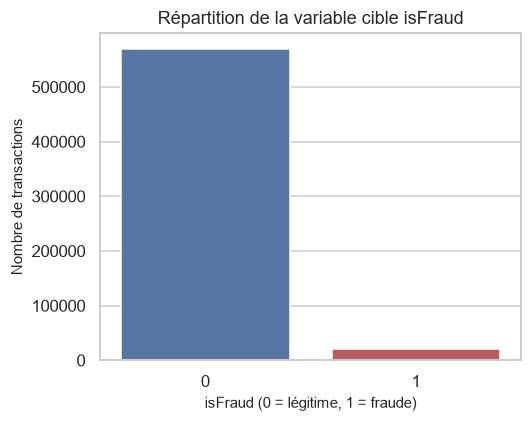

In [8]:
# Répartition de la variable cible isFraud
cible = df_raw["isFraud"].value_counts().to_frame("effectif")
cible["pourcentage"] = (df_raw["isFraud"].value_counts(normalize=True) * 100).round(3)
display(cible)

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="isFraud", data=df_raw, ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_title("Répartition de la variable cible isFraud")
ax.set_xlabel("isFraud (0 = légitime, 1 = fraude)")
ax.set_ylabel("Nombre de transactions")
plt.tight_layout()
plt.show()

### Interprétation — Variable cible

Environ 96,5 % des transactions sont légitimes contre environ 3,5 % de fraudes : le jeu de données est fortement déséquilibré (rapport d'environ 1 fraude pour 27 transactions légitimes).

**Ce que cela signifie.** Un classifieur qui prédirait systématiquement « légitime » obtiendrait environ 96,5 % d'accuracy sans détecter aucune fraude. L'accuracy est donc une métrique inadaptée ; on privilégiera rappel, précision, F1, AUC-ROC et AUC-PR, ainsi que des techniques de rééquilibrage ou de pondération des classes.

**Intérêt métier.** Le coût d'une fraude non détectée est généralement bien supérieur à celui d'une fausse alerte : le seuil de décision devra être choisi selon une logique de coût métier.

## 2.8 Dictionnaire synthétique des variables

In [9]:
# Dictionnaire synthétique (familles de variables du jeu IEEE-CIS)
dictionnaire = pd.DataFrame([
    ["TransactionID", "Identifiant", "Identifiant unique de la transaction (clé de jointure)"],
    ["isFraud", "Cible", "1 si la transaction est frauduleuse, 0 sinon"],
    ["TransactionDT", "Temps", "Décalage en secondes par rapport à une date de référence"],
    ["TransactionAmt", "Montant", "Montant de la transaction en USD"],
    ["ProductCD", "Catégorielle", "Code du produit acheté"],
    ["card1 - card6", "Carte", "Attributs de la carte de paiement (émetteur, type, réseau, catégorie)"],
    ["addr1, addr2", "Adresse", "Zones de facturation (région, pays)"],
    ["dist1, dist2", "Distance", "Distances (adresse, IP, etc.), anonymisées"],
    ["P_emaildomain, R_emaildomain", "Email", "Domaine email de l'acheteur et du destinataire"],
    ["C1 - C14", "Comptage", "Nombres (adresses associées à la carte, etc.), anonymisés"],
    ["D1 - D15", "Délai", "Délais entre événements (jours depuis une transaction précédente, etc.)"],
    ["M1 - M9", "Correspondance", "Indicateurs de concordance (nom, carte, adresse), valeurs T/F"],
    ["V1 - V339", "Vesta", "Variables d'ingénierie propriétaires de Vesta (rang, comptages, entités)"],
    ["id_01 - id_11", "Identité numérique", "Scores et métriques d'identité / réseau (anonymisés)"],
    ["id_12 - id_38", "Identité catégorielle", "Caractéristiques de l'appareil, du navigateur, de la résolution, etc."],
    ["DeviceType", "Appareil", "Type d'appareil (desktop, mobile)"],
    ["DeviceInfo", "Appareil", "Modèle ou identifiant de l'appareil"],
], columns=["Variable(s)", "Famille", "Description"])
dictionnaire

,Variable(s),Famille,Description
0,TransactionID,Identifiant,Identifiant unique de la transaction (clé de j...
1,isFraud,Cible,"1 si la transaction est frauduleuse, 0 sinon"
2,TransactionDT,Temps,Décalage en secondes par rapport à une date de...
3,TransactionAmt,Montant,Montant de la transaction en USD
4,ProductCD,Catégorielle,Code du produit acheté
5,card1 - card6,Carte,"Attributs de la carte de paiement (émetteur, t..."
6,"addr1, addr2",Adresse,"Zones de facturation (région, pays)"
7,"dist1, dist2",Distance,"Distances (adresse, IP, etc.), anonymisées"
8,"P_emaildomain, R_emaildomain",Email,Domaine email de l'acheteur et du destinataire
9,C1 - C14,Comptage,"Nombres (adresses associées à la carte, etc.),..."


# CHAPITRE 3 — PRÉPARATION DES DONNÉES

## 3.1 Inspection initiale

In [10]:
# Réduction mémoire : conversion des float64 / int64 en types plus légers
cols_float = df_raw.select_dtypes("float64").columns
cols_int   = df_raw.select_dtypes("int64").columns
df_raw[cols_float] = df_raw[cols_float].astype("float32")
df_raw[cols_int]   = df_raw[cols_int].apply(pd.to_numeric, downcast="integer")

print(f"Mémoire après optimisation : {df_raw.memory_usage(deep=True).sum() / 1024**2:,.0f} Mo")
print("\nTypes :")
print(df_raw.dtypes.value_counts())

Mémoire après optimisation : 1,603 Mo

Types :
float32    399
object      31
int32        2
int8         1
int16        1
Name: count, dtype: int64


### Interprétation — Optimisation des types

La conversion en float32 et en entiers de taille réduite diminue sensiblement l'empreinte mémoire du DataFrame.

La perte de précision liée au float32 est négligeable pour cette étude et permet de manipuler le jeu de données complet sur une machine standard.

**Intérêt métier.** Une préparation économe en ressources facilite l'industrialisation ultérieure du pipeline.

In [11]:
# Synthèse des valeurs manquantes (volume et pourcentage par colonne)
manquants = pd.DataFrame({
    "n_manquants": df_raw.isna().sum(),
    "pct_manquants": df_raw.isna().mean() * 100,
    "dtype": df_raw.dtypes.astype(str)
}).sort_values("pct_manquants", ascending=False)

print(f"Colonnes sans valeur manquante   : {(manquants.n_manquants == 0).sum()}")
print(f"Colonnes avec valeurs manquantes : {(manquants.n_manquants > 0).sum()}")
print(f"Cellules manquantes au total     : {df_raw.isna().sum().sum():,} "
      f"({df_raw.isna().sum().sum() / df_raw.size * 100:.1f} % du jeu de données)")
manquants.head(15)

Colonnes sans valeur manquante   : 20
Colonnes avec valeurs manquantes : 414
Cellules manquantes au total     : 115,523,073 (45.1 % du jeu de données)


,n_manquants,pct_manquants,dtype
id_24,585793,99.196,float32
id_25,585408,99.131,float32
id_07,585385,99.127,float32
id_08,585385,99.127,float32
id_21,585381,99.126,float32
id_26,585377,99.126,float32
id_27,585371,99.125,object
id_23,585371,99.125,object
id_22,585371,99.125,float32
dist2,552913,93.628,float32


In [12]:
# Doublons : lignes entièrement identiques et doublons sur la clé TransactionID
print("Lignes entièrement dupliquées     :", df_raw.duplicated().sum())
print("TransactionID dupliqués           :", df_raw["TransactionID"].duplicated().sum())

Lignes entièrement dupliquées     : 0
TransactionID dupliqués           : 0


### Interprétation — Inspection initiale

Une proportion importante des colonnes présente des valeurs manquantes (de quelques pourcents à plus de 90 %), en particulier les colonnes id_* et certaines familles V, D et dist. Aucun doublon sur TransactionID n'est attendu, et les lignes entièrement dupliquées sont nulles ou quasi nulles.

Les valeurs manquantes ne sont pas aléatoires : elles reflètent la structure de collecte (informations d'identité disponibles pour une partie des transactions seulement). L'unicité de TransactionID confirme que la fusion n'a pas créé de lignes parasites.

Le traitement des valeurs manquantes est le principal chantier de préparation : une stratégie inadaptée (suppression ou imputation brutale) risquerait d'effacer un signal utile à la détection de fraude.

## 3.2 Analyse des valeurs manquantes

,nb_colonnes
tranche,
0 %,20
0-10 %,92
10-30 %,90
30-50 %,18
50-80 %,140
> 80 %,74


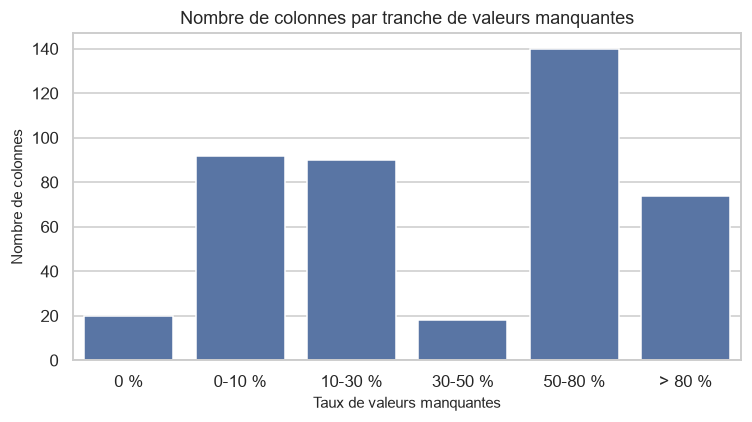

In [13]:
# Classement des colonnes par niveau de valeurs manquantes
bins   = [-0.01, 0, 10, 30, 50, 80, 100]
labels = ["0 %", "0-10 %", "10-30 %", "30-50 %", "50-80 %", "> 80 %"]
manquants["tranche"] = pd.cut(manquants["pct_manquants"], bins=bins, labels=labels)

repartition = manquants["tranche"].value_counts().reindex(labels).to_frame("nb_colonnes")
display(repartition)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=repartition.index, y=repartition["nb_colonnes"], ax=ax, color="#4C72B0")
ax.set_title("Nombre de colonnes par tranche de valeurs manquantes")
ax.set_xlabel("Taux de valeurs manquantes")
ax.set_ylabel("Nombre de colonnes")
plt.tight_layout()
plt.show()

In [14]:
# Variables critiques : 30 colonnes les plus incomplètes
manquants.head(30)[["n_manquants", "pct_manquants"]]

,n_manquants,pct_manquants
id_24,585793,99.196
id_25,585408,99.131
id_07,585385,99.127
id_08,585385,99.127
id_21,585381,99.126
id_26,585377,99.126
id_27,585371,99.125
id_23,585371,99.125
id_22,585371,99.125
dist2,552913,93.628


### Interprétation — Volume et pourcentage de valeurs manquantes

Les colonnes se répartissent entre colonnes complètes, partiellement renseignées et colonnes quasi vides. Les colonnes critiques (plus de 80 % de manquants) appartiennent surtout aux familles id_* et D.

Une colonne presque entièrement vide apporte peu d'information exploitable et peut dégrader les modèles ; à l'inverse, une colonne modérément incomplète peut être imputée de manière fiable.

Cette analyse justifie un seuil de suppression explicite et documenté, accepté par les parties prenantes du projet.

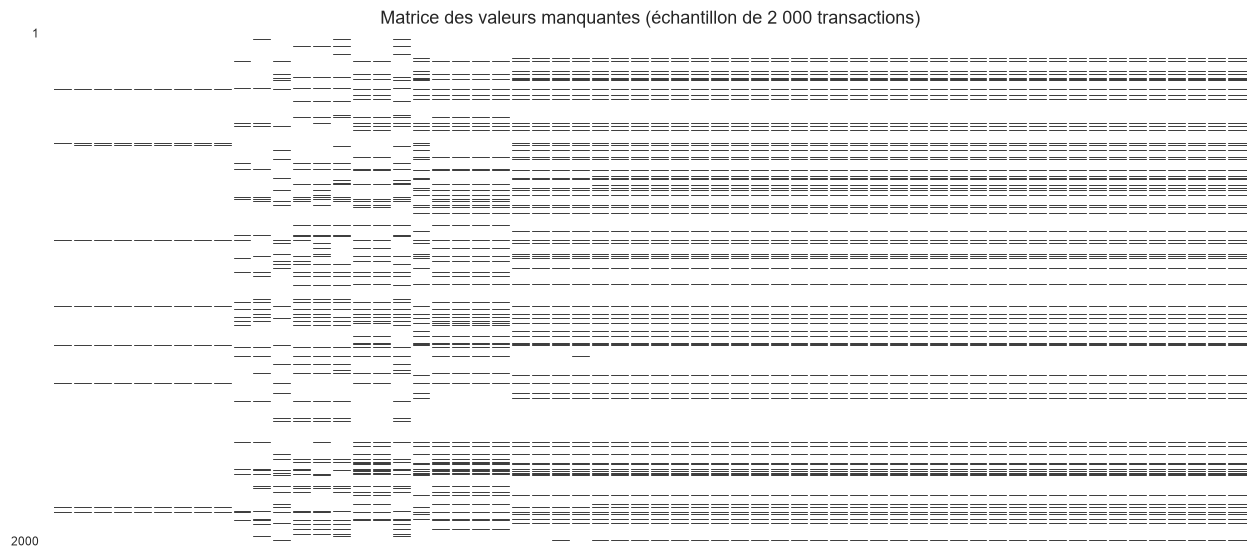

In [15]:
# Missing matrix (échantillon aléatoire pour la lisibilité) - 60 colonnes les plus incomplètes non vides
echantillon = df_raw.sample(2000, random_state=SEED)
cols_matrix = manquants[(manquants.pct_manquants > 0)].head(60).index
msno.matrix(echantillon[cols_matrix], figsize=(14, 6), sparkline=False, fontsize=7)
plt.title("Matrice des valeurs manquantes (échantillon de 2 000 transactions)", fontsize=12)
plt.show()

### Interprétation — Missing matrix

La matrice montre des blocs de colonnes dont les valeurs manquantes apparaissent simultanément sur les mêmes lignes (bandes blanches verticales continues).

Les valeurs manquantes sont structurées par blocs (MNAR / dépendantes de la source) et non uniformément aléatoires : c'est typique de tables fusionnées où certaines familles ne sont renseignées que pour certaines transactions.

Ces blocs suggèrent que la simple présence d'une information d'identité peut être un signal. On pourra créer des indicateurs de présence.

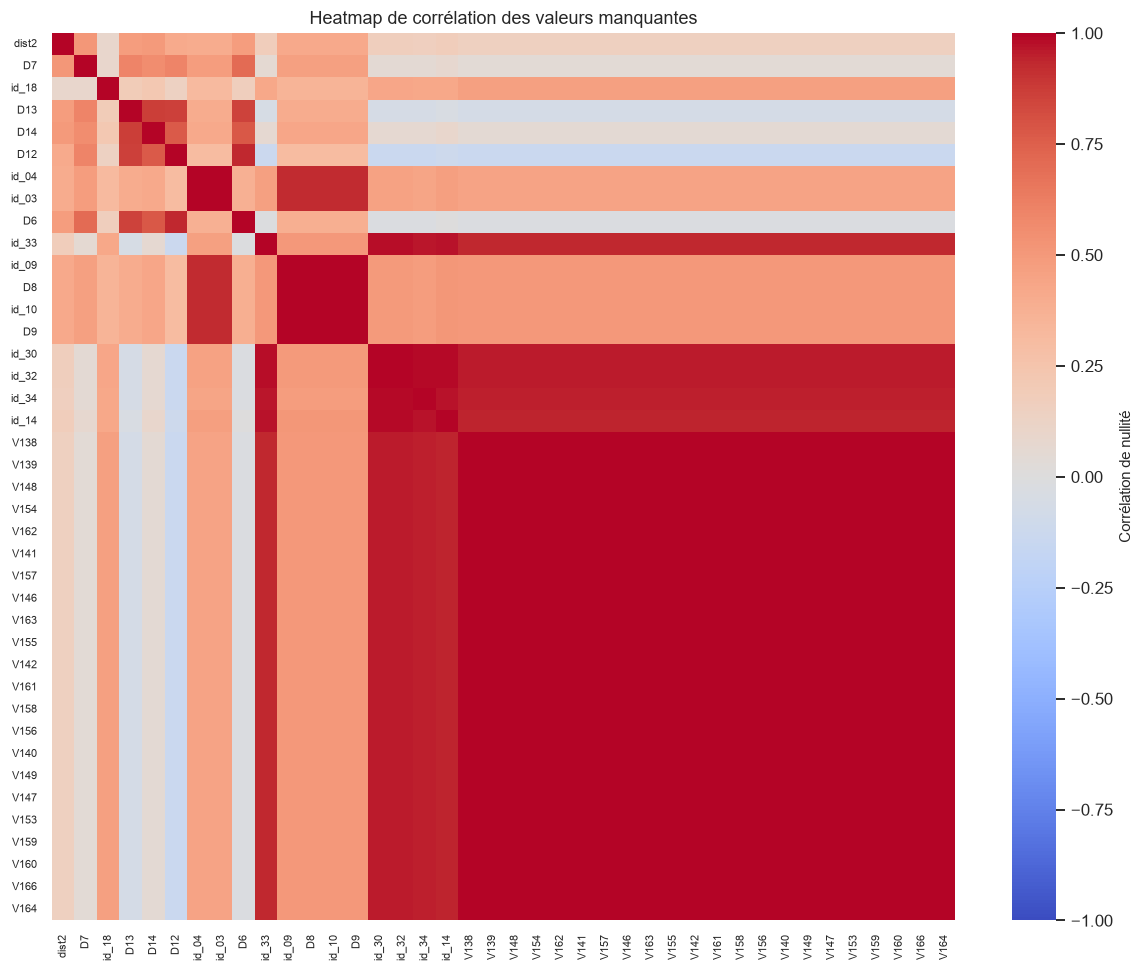

In [16]:
# Heatmap de corrélation de la nullité (colonnes avec manquants, échantillon)
cols_heat = manquants[(manquants.pct_manquants > 5) & (manquants.pct_manquants < 95)].head(40).index
corr_null = echantillon[cols_heat].isna().astype(int).corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_null, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={"label": "Corrélation de nullité"})
plt.title("Heatmap de corrélation des valeurs manquantes")
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

### Interprétation — Heatmap de nullité

La heatmap fait apparaître des blocs de corrélation de nullité proches de 1 : des groupes de colonnes sont manquants ou présents ensemble.

Ces groupes proviennent de la même source ou du même mécanisme de calcul (par exemple les variables V d'une même famille). Cela indique une forte redondance d'information entre colonnes d'un même bloc.


La redondance autorise une réduction de dimension (ACP) sans perte d'information majeure.

## 3.3 Traitement des valeurs manquantes

### Suppression des variables à trop fort taux de manquants

Seuil retenu : **50 %**. Les colonnes dont plus de la moitié des valeurs sont absentes sont retirées, à l'exception de la variable cible et de l'identifiant. Ce seuil est un compromis classique ; il pourra être discuté.

In [17]:
SEUIL_NA = 50  # %

# DeviceType est conservé malgré son taux de manquants (analyse bivariée demandée) :
# les valeurs absentes seront codées "Inconnu" lors de l'imputation
cols_a_supprimer = manquants[manquants.pct_manquants > SEUIL_NA].index.difference(["isFraud", "TransactionID", "DeviceType"])
print(f"Colonnes supprimées (> {SEUIL_NA} % de manquants) : {len(cols_a_supprimer)}")

df = df_raw.drop(columns=cols_a_supprimer).copy()
print(f"Dimensions avant : {df_raw.shape}  ->  après : {df.shape}")

Colonnes supprimées (> 50 % de manquants) : 213
Dimensions avant : (590540, 434)  ->  après : (590540, 221)


### Interprétation — Suppression des colonnes trop incomplètes

Plusieurs dizaines à plus d'une centaine de colonnes sont supprimées, principalement les id_*, DeviceInfo et plusieurs colonnes D et V.

Imputer une colonne vide à plus de 50 % reviendrait à inventer l'essentiel de l'information : la suppression est plus prudente statistiquement.

Cette réduction allège le jeu de données et accélère les modèles. Le choix du seuil doit être documenté dans le rapport comme hypothèse de travail.

### Imputation

Stratégie : **médiane** pour les variables numériques (robuste aux valeurs extrêmes), **modalité la plus fréquente** pour les variables catégorielles. On crée un indicateur de présence pour les informations d'identité avant d'imputer, afin de conserver le signal « information absente ».

In [18]:
# Indicateur de présence d'identité (avant imputation, pour conserver le signal)
df["has_identity"] = df_raw["DeviceType"].notna().astype("int8")

# DeviceType : l'absence d'information devient une modalité à part entière
df["DeviceType"] = df["DeviceType"].fillna("Inconnu")

cols_num = df.select_dtypes(include="number").columns.difference(["TransactionID", "isFraud", "has_identity"])
cols_cat = df.select_dtypes(include="object").columns

# Imputation numérique par la médiane
df[cols_num] = df[cols_num].fillna(df[cols_num].median())

# Imputation catégorielle par le mode
df[cols_cat] = df[cols_cat].fillna(df[cols_cat].mode().iloc[0])

print("Valeurs manquantes restantes :", df.isna().sum().sum())

Valeurs manquantes restantes : 0


### Interprétation — Imputation

Après imputation, le jeu de données ne contient plus aucune valeur manquante.

L'imputation par la médiane préserve la tendance centrale sans être affectée par les valeurs extrêmes, mais elle réduit artificiellement la variance des variables fortement incomplètes. Pour les modèles à base d'arbres, une imputation par une valeur hors plage ou le traitement natif des NaN (XGBoost) serait une alternative.

L'indicateur has_identity transforme une limite du jeu de données (absence d'information) en variable explicative potentiellement discriminante.

## 3.4 Analyse des doublons

In [19]:
# Doublons après nettoyage, sur l'ensemble des variables hors identifiant
n_doublons = df.drop(columns="TransactionID").duplicated().sum()
print(f"Doublons (hors TransactionID) : {n_doublons:,} ({n_doublons / len(df) * 100:.3f} %)")

# Les doublons sont-ils associés à la fraude ?
masque_dup = df.drop(columns="TransactionID").duplicated(keep=False)
print("\nTaux de fraude parmi les lignes dupliquées vs non dupliquées :")
print(df.groupby(masque_dup)["isFraud"].mean().mul(100).round(3).rename({False: "Non dupliquées", True: "Dupliquées"}))

Doublons (hors TransactionID) : 3 (0.001 %)

Taux de fraude parmi les lignes dupliquées vs non dupliquées :
Non dupliquées   3.499
Dupliquées       0.000
Name: isFraud, dtype: float64


### Interprétation — Doublons

Le nombre de lignes dupliquées (hors identifiant) est faible, voire nul. La comparaison du taux de fraude entre lignes dupliquées et non dupliquées éclaire leur nature.

Les doublons post-imputation peuvent résulter de l'imputation elle-même (transactions très pauvres en information) plutôt que d'une vraie duplication. Comme chaque TransactionID est unique, ces lignes correspondent à des transactions distinctes.

On conserve les lignes : une suppression ferait disparaître des transactions réelles, dont d'éventuelles fraudes. Les doublons ne sont signalés que pour traçabilité.

## 3.5 Analyse des valeurs aberrantes

In [20]:
# Variables étudiées pour les valeurs aberrantes
cols_out = ["TransactionAmt", "C1", "C2", "C13", "D1", "dist1"]
cols_out = [c for c in cols_out if c in df.columns]

# --- Méthode IQR ---
Q1, Q3 = df[cols_out].quantile(0.25), df[cols_out].quantile(0.75)
IQR = Q3 - Q1
masque_iqr = (df[cols_out] < (Q1 - 1.5 * IQR)) | (df[cols_out] > (Q3 + 1.5 * IQR))

# --- Méthode Z-Score (|z| > 3) ---
z = df[cols_out].apply(stats.zscore)
masque_z = z.abs() > 3

resume_out = pd.DataFrame({
    "n_IQR": masque_iqr.sum(),
    "pct_IQR": masque_iqr.mean() * 100,
    "n_ZScore": masque_z.sum(),
    "pct_ZScore": masque_z.mean() * 100
})
resume_out

,n_IQR,pct_IQR,n_ZScore,pct_ZScore
TransactionAmt,66482,11.258,10093,1.709
C1,59535,10.081,2024,0.343
C2,62214,10.535,2335,0.395
C13,75631,12.807,19701,3.336
D1,75153,12.726,11650,1.973


In [21]:
# Taux de fraude parmi les valeurs aberrantes (IQR) pour chaque variable
taux = {c: [df.loc[~masque_iqr[c], "isFraud"].mean() * 100, df.loc[masque_iqr[c], "isFraud"].mean() * 100]
        for c in cols_out}
pd.DataFrame(taux, index=["Taux de fraude hors aberrants (%)", "Taux de fraude aberrants (%)"]).T

,Taux de fraude hors aberrants (%),Taux de fraude aberrants (%)
TransactionAmt,3.299,5.072
C1,2.936,8.524
C2,2.898,8.599
C13,3.716,2.020
D1,3.846,1.120


### Interprétation — Détection IQR et Z-Score

La méthode IQR signale nettement plus de valeurs aberrantes que le Z-Score, car les distributions sont fortement asymétriques à droite ; le Z-Score, qui suppose une distribution proche de la normale, est moins sensible. Le taux de fraude parmi les valeurs aberrantes diffère de celui des valeurs normales.

Les observations extrêmes ne sont pas du bruit : elles représentent des comportements réels (gros montants, nombre élevé d'adresses associées à une carte) potentiellement liés à la fraude.

Supprimer ces valeurs reviendrait à supprimer une partie du signal frauduleux. On privilégie leur conservation, avec transformation (log) ou modèles robustes.

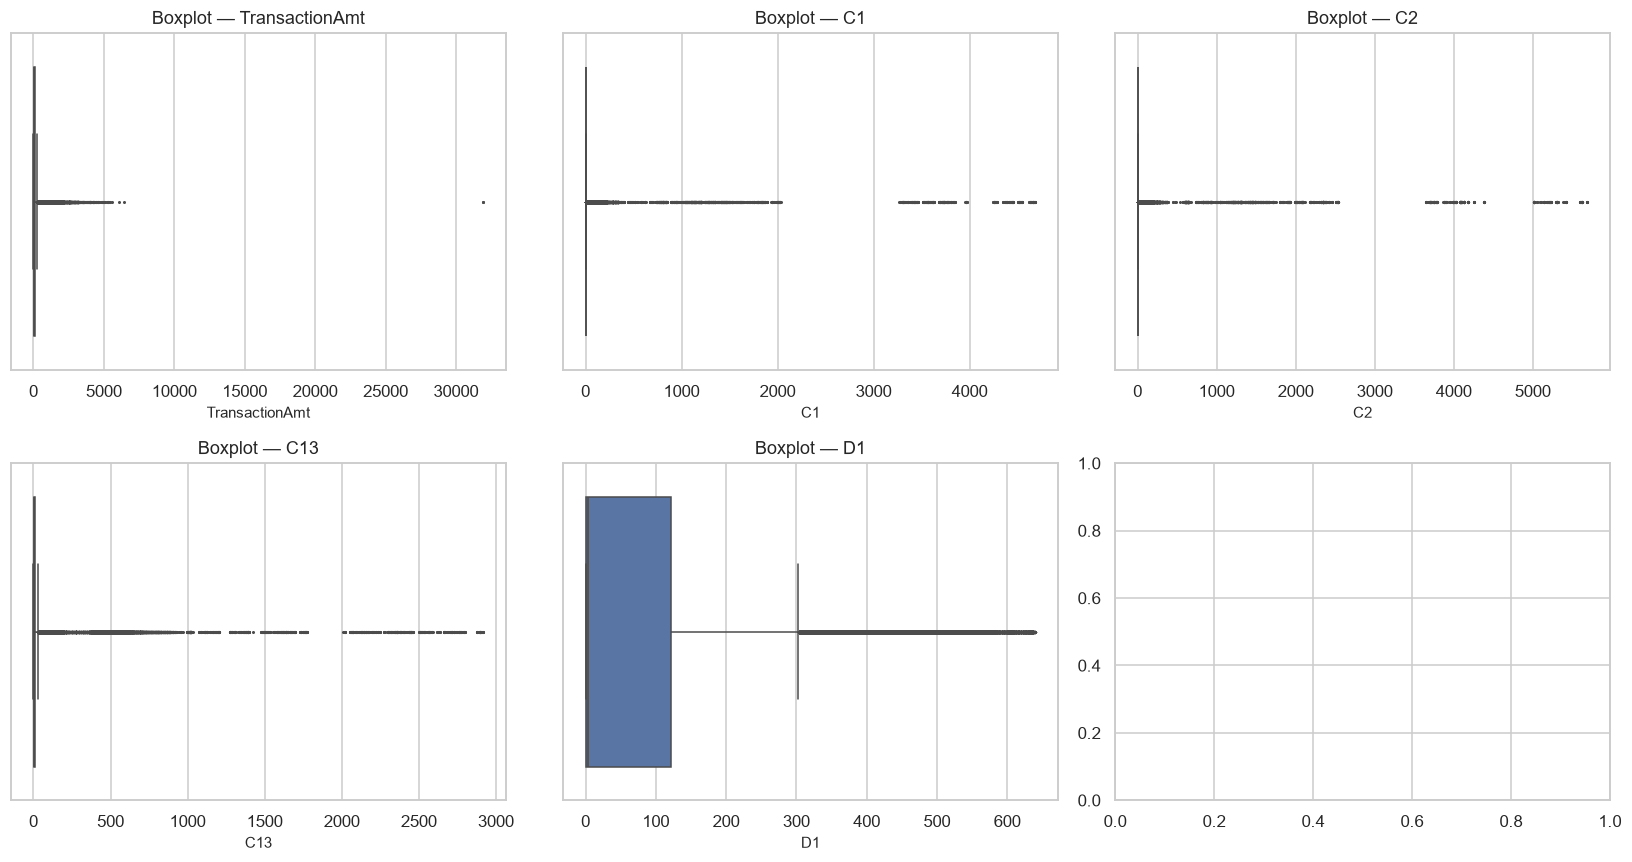

In [22]:
# Boxplots (échelle brute puis log) et distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cols_out):
    sns.boxplot(x=df[c], ax=ax, color="#4C72B0", fliersize=1)
    ax.set_title(f"Boxplot — {c}")
plt.tight_layout()
plt.show()

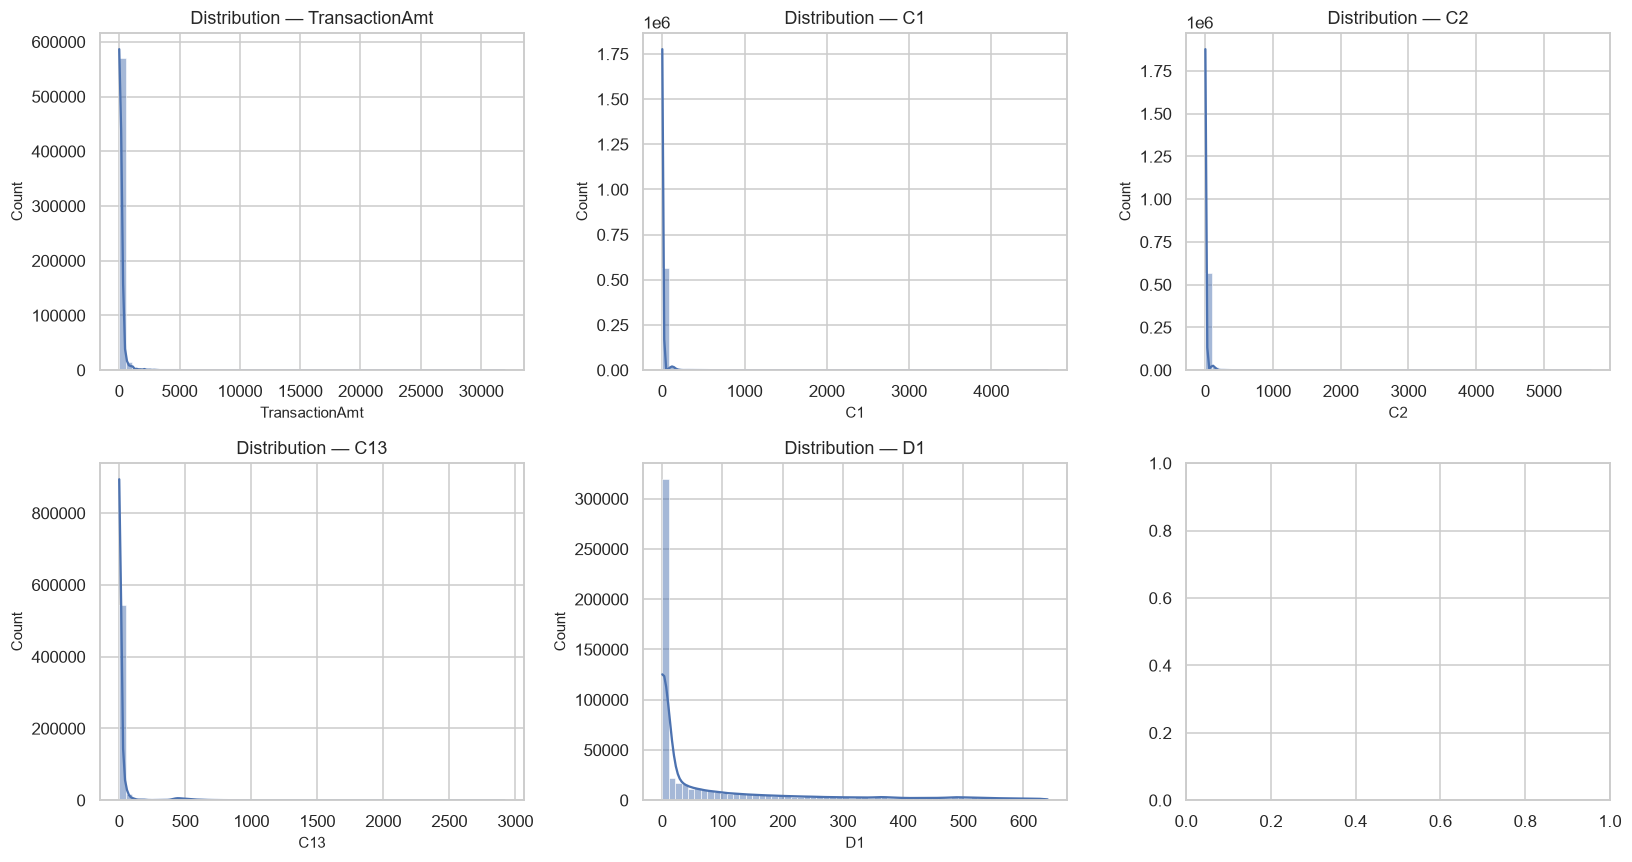

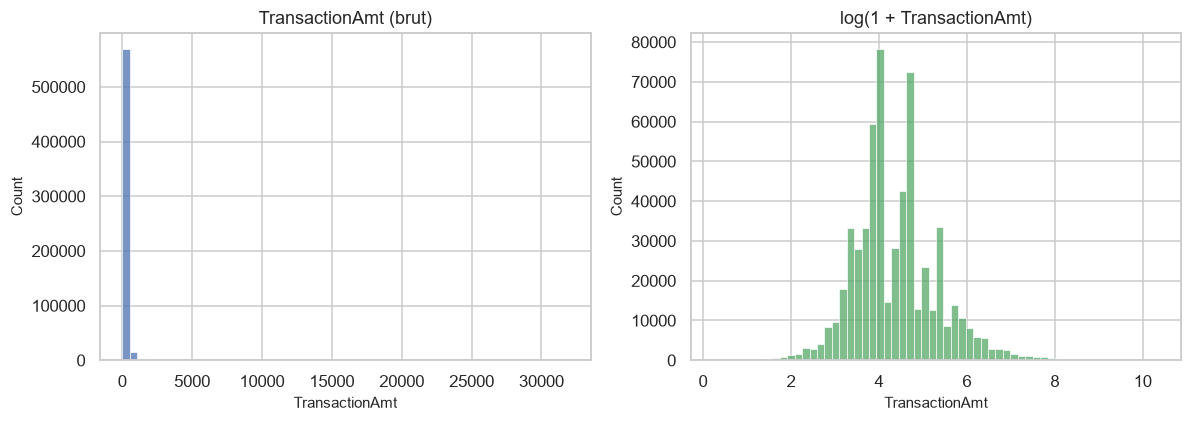

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cols_out):
    sns.histplot(df[c], bins=60, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution — {c}")
plt.tight_layout()
plt.show()

# Effet d'une transformation logarithmique sur TransactionAmt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["TransactionAmt"], bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("TransactionAmt (brut)")
sns.histplot(np.log1p(df["TransactionAmt"]), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title("log(1 + TransactionAmt)")
plt.tight_layout()
plt.show()

### Interprétation — Boxplots et distributions

Les boxplots montrent de très nombreux points au-delà des moustaches et les histogrammes une forte asymétrie à droite. La transformation logarithmique de TransactionAmt rend la distribution beaucoup plus symétrique.

Les variables suivent des lois à queue lourde (type log-normale) : les tests et modèles supposant la normalité doivent être utilisés avec précaution ou après transformation.

La transformation log est une alternative à la suppression : elle réduit l'influence des valeurs extrêmes tout en conservant les observations.

## 3.6 Feature Engineering

TransactionDT est un décalage en secondes depuis une date de référence. On en dérive :
- **heure** : heure de la journée (0–23)
- **jour** : jour de la semaine relatif (0–6), l'origine étant inconnue
- **catégorie de montant** : tranches de montant (très faible à très élevé)

In [24]:
# Variables temporelles dérivées de TransactionDT (en secondes)
df["heure"] = ((df["TransactionDT"] // 3600) % 24).astype("int8")
df["jour"]  = ((df["TransactionDT"] // 86400) % 7).astype("int8")   # 0-6 relatif (origine inconnue)

# Catégorie de montant par quantiles (5 classes équilibrées)
df["categorie_montant"] = pd.qcut(
    df["TransactionAmt"], q=5,
    labels=["Très faible", "Faible", "Moyen", "Élevé", "Très élevé"]
)

# Log du montant (réduction de l'asymétrie)
df["log_montant"] = np.log1p(df["TransactionAmt"])

df[["TransactionDT", "heure", "jour", "TransactionAmt", "categorie_montant", "log_montant"]].head(8)

,TransactionDT,heure,jour,TransactionAmt,categorie_montant,log_montant
0,86400,0,1,68.500,Moyen,4.241
1,86401,0,1,29.000,Très faible,3.401
2,86469,0,1,59.000,Moyen,4.094
3,86499,0,1,50.000,Faible,3.932
4,86506,0,1,50.000,Faible,3.932
5,86510,0,1,49.000,Faible,3.912
6,86522,0,1,159.000,Élevé,5.075
7,86529,0,1,422.500,Très élevé,6.049


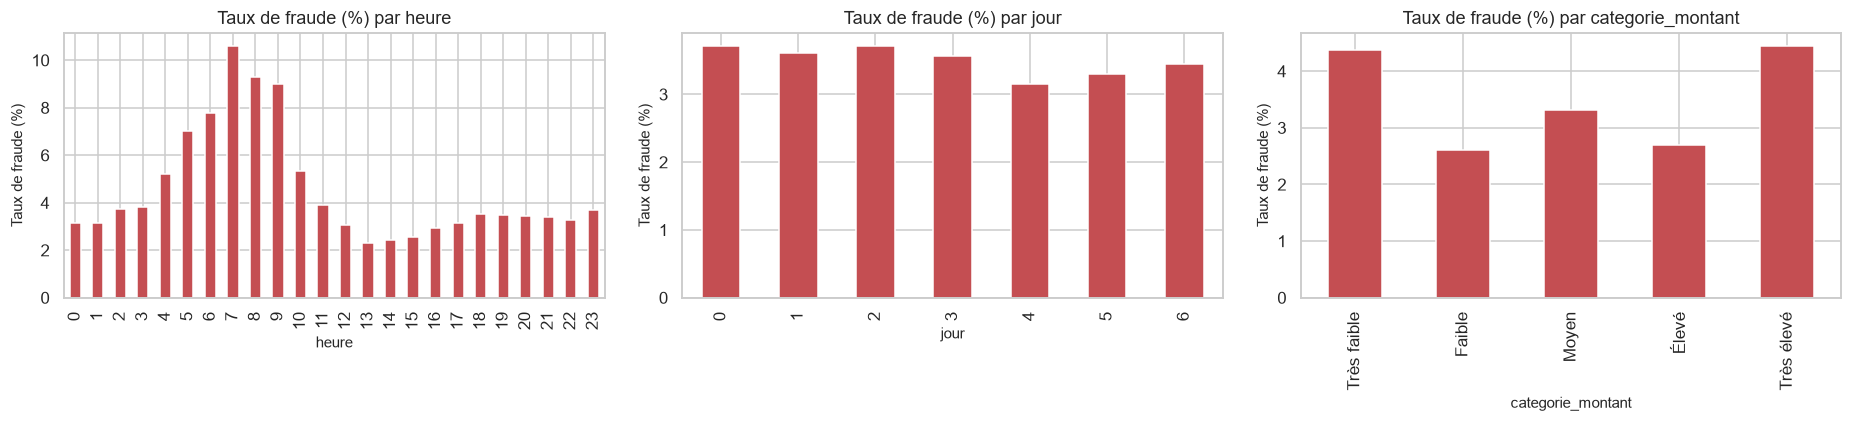

In [25]:
# Taux de fraude par heure, jour et catégorie de montant
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, c in zip(axes, ["heure", "jour", "categorie_montant"]):
    (df.groupby(c, observed=True)["isFraud"].mean() * 100).plot(kind="bar", ax=ax, color="#C44E52")
    ax.set_title(f"Taux de fraude (%) par {c}")
    ax.set_ylabel("Taux de fraude (%)")
plt.tight_layout()
plt.show()

### Interprétation — Feature Engineering

Les trois nouvelles variables sont créées. Le taux de fraude varie selon l'heure de la journée (certaines heures, notamment nocturnes, présentent un taux plus élevé) et selon la catégorie de montant.

Des motifs temporels et de montant existent dans les données : ils offrent un pouvoir discriminant que la variable brute TransactionDT, peu lisible, ne rendait pas visible. L'heure est calculée relativement à l'origine inconnue de TransactionDT ; elle indique donc un rythme journalier, pas nécessairement l'heure locale réelle.

Ces variables nourriront le tableau de bord Power BI (analyse temporelle) et les modèles prédictifs.

## 3.7 Transformation des variables catégorielles

- **Label Encoding** : variables à nombreuses modalités ou ordinales (domaines email, M1–M9, card4/card6 pour le jeu final).
- **One Hot Encoding** : variables nominales à faible cardinalité (ProductCD, DeviceType si présent).

In [26]:
# Cardinalité des variables catégorielles restantes
cols_cat = df.select_dtypes(include=["object", "category"]).columns.tolist()
df[cols_cat].nunique().sort_values(ascending=False)

P_emaildomain        59
categorie_montant     5
ProductCD             5
card6                 4
card4                 4
M4                    3
DeviceType            3
M3                    2
M2                    2
M1                    2
M6                    2
dtype: int64

In [27]:
# Séparation selon la cardinalité (seuil : 6 modalités)
cardinalite = df[cols_cat].nunique()
cols_ohe   = cardinalite[cardinalite <= 6].index.difference(["categorie_montant"]).tolist()
cols_label = cardinalite[cardinalite > 6].index.tolist()
print("One Hot Encoding :", cols_ohe)
print("Label Encoding   :", cols_label)

# --- Label Encoding (copie dédiée) ---
df_prepared = df.copy()
for c in cols_label:
    df_prepared[c] = LabelEncoder().fit_transform(df_prepared[c].astype(str))

# Catégorie de montant : encodage ordinal
ordre = {"Très faible": 0, "Faible": 1, "Moyen": 2, "Élevé": 3, "Très élevé": 4}
df_prepared["categorie_montant_code"] = df["categorie_montant"].map(ordre).astype("int8")

# --- One Hot Encoding ---
df_prepared = pd.get_dummies(df_prepared, columns=cols_ohe, drop_first=True, dtype="int8")

print("Dimensions après encodage :", df_prepared.shape)

One Hot Encoding : ['DeviceType', 'M1', 'M2', 'M3', 'M4', 'M6', 'ProductCD', 'card4', 'card6']
Label Encoding   : ['P_emaildomain']
Dimensions après encodage : (590540, 236)


### Interprétation — Label Encoding et One Hot Encoding

Les variables à faible cardinalité (par exemple ProductCD, card4, card6, M1–M9) sont éclatées en indicateurs binaires ; les variables à forte cardinalité (domaines email) sont encodées par entiers.

Le One Hot Encoding évite d'introduire un ordre artificiel entre modalités mais augmente le nombre de colonnes ; le Label Encoding reste compact mais impose un ordre arbitraire, acceptable pour les modèles à base d'arbres, moins pour les modèles linéaires.

Le choix de l'encodage doit être cohérent avec le modèle final : Random Forest et XGBoost tolèrent le Label Encoding, la régression logistique nécessite plutôt du One Hot Encoding ou un encodage par fréquence.

## 3.8 Mise à l'échelle

In [28]:
# Variables numériques continues à mettre à l'échelle (hors identifiants, cible, indicateurs)
cols_a_scaler = ["TransactionAmt", "log_montant", "C1", "C2", "C13"]
cols_a_scaler = [c for c in cols_a_scaler if c in df_prepared.columns]

# StandardScaler : moyenne 0, écart-type 1
df_standard = pd.DataFrame(StandardScaler().fit_transform(df_prepared[cols_a_scaler]),
                           columns=cols_a_scaler, index=df_prepared.index)

# MinMaxScaler : valeurs dans [0, 1]
df_minmax = pd.DataFrame(MinMaxScaler().fit_transform(df_prepared[cols_a_scaler]),
                         columns=cols_a_scaler, index=df_prepared.index)

# Contrôle des statistiques
print("StandardScaler :")
display(df_standard.describe().loc[["mean", "std", "min", "max"]])
print("MinMaxScaler :")
display(df_minmax.describe().loc[["mean", "std", "min", "max"]])

StandardScaler :


,TransactionAmt,log_montant,C1,C2,C13
mean,0.000,-0.000,0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000
min,-0.564,-4.438,-0.106,-0.099,-0.252
max,132.974,6.390,34.970,36.696,22.305


MinMaxScaler :


,TransactionAmt,log_montant,C1,C2,C13
mean,0.004,0.410,0.003,0.003,0.011
std,0.007,0.092,0.029,0.027,0.044
min,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000


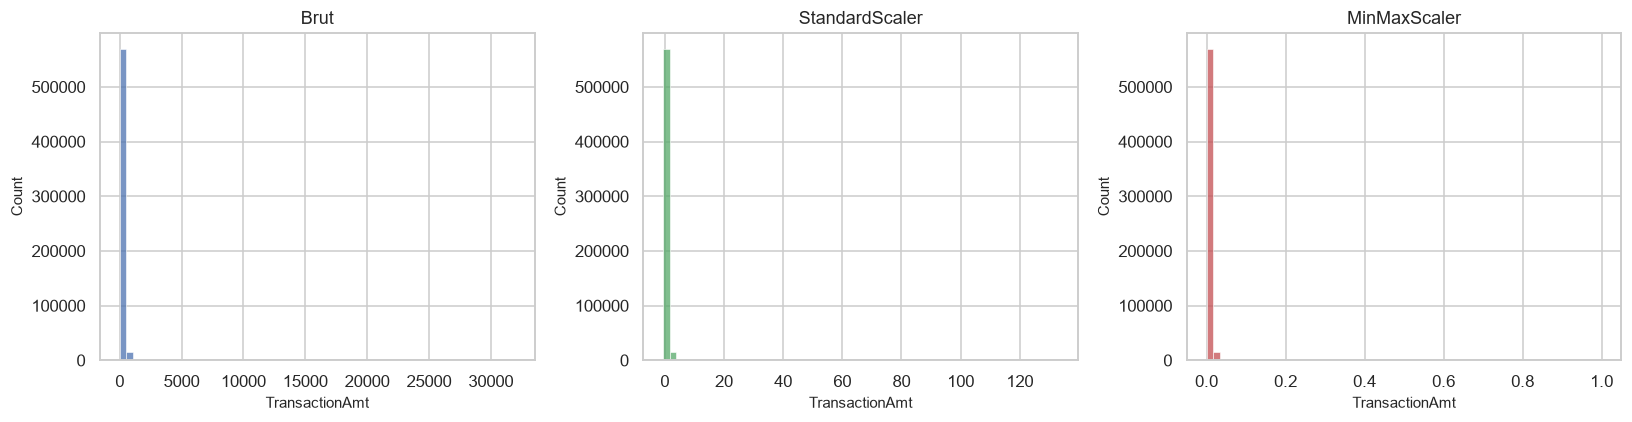

In [29]:
# Comparaison visuelle sur TransactionAmt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_prepared["TransactionAmt"], bins=60, ax=axes[0], color="#4C72B0"); axes[0].set_title("Brut")
sns.histplot(df_standard["TransactionAmt"], bins=60, ax=axes[1], color="#55A868"); axes[1].set_title("StandardScaler")
sns.histplot(df_minmax["TransactionAmt"], bins=60, ax=axes[2], color="#C44E52"); axes[2].set_title("MinMaxScaler")
plt.tight_layout()
plt.show()

### Interprétation — Mise à l'échelle

Après StandardScaler, les variables ont une moyenne proche de 0 et un écart-type proche de 1 ; après MinMaxScaler, elles sont comprises entre 0 et 1. La forme de la distribution est inchangée, seule l'échelle varie.

Les deux transformations sont linéaires et ne corrigent pas l'asymétrie. StandardScaler est le choix de référence pour l'ACP, la régression logistique et les méthodes à base de distances. MinMaxScaler est sensible aux valeurs extrêmes : un seul montant très élevé compresse le reste de la distribution.

Pour la production, le scaler devra être ajusté sur l'échantillon d'entraînement uniquement, puis sauvegardé avec le modèle afin d'éviter toute fuite de données (data leakage).

## 3.9 Sauvegarde du jeu de données préparé

In [32]:
# Sauvegarde pour le notebook 02 : on conserve aussi la version avant encodage (analyse EDA)
df.to_parquet("df_clean.parquet", index=False)            # nettoyé, imputé, avec features (lisible pour l'EDA)
df_prepared.to_parquet("df_prepared.parquet", index=False) # encodé (modélisation)

print("df_clean    :", df.shape)
print("df_prepared :", df_prepared.shape)

df_clean    : (590540, 226)
df_prepared : (590540, 236)


### Interprétation — Sauvegarde

Deux fichiers sont produits : df_clean.parquet (variables lisibles, utilisé pour l'EDA) et df_prepared.parquet (variables encodées, utilisé pour la modélisation).

Séparer les deux versions évite de dégrader la lisibilité de l'analyse exploratoire tout en préparant la modélisation.

Le chaînage des notebooks via des fichiers intermédiaires garantit la traçabilité entre les chapitres du rapport.